# Questão 5: Autoencoders na base Fashion-MNIST

A Fashion-MNIST tem 70 mil imagens em tons de cinza, de 28 x 28 pixels, de 10 tipos de roupas e acessórios (camiseta, calça, vestido, tênis, bolsa etc.).

Um autoencoder é uma rede que aprende a copiar a entrada para a saída, mas passando por um "gargalo":
- o encoder comprime a imagem (784 pixels) em poucos números, o chamado espaço latente;
- o decoder tenta reconstruir a imagem original só a partir desses números.

Como o gargalo é pequeno, a rede é obrigada a guardar só o que é mais importante na imagem.

- Item a: treinamos três autoencoders com espaços latentes de 100, 50 e 30 números e comparamos as reconstruções.
- Item b: treinamos um autoencoder para remover ruído das imagens.

## Bibliotecas

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import datasets
from tqdm import tqdm

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

PASTA_DADOS = Path("../data/fashion_mnist")
PASTA_FIGURAS = Path("../figures/q5")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

CLASSES = ["camiseta", "calça", "suéter", "vestido", "casaco", "sandália", "camisa", "tênis", "bolsa", "bota"]
TAMANHOS_LATENTE = [100, 50, 30]
NIVEL_RUIDO = 0.3

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
Fixa a "semente" dos sorteios (pesos iniciais, embaralhamento, ruído) e pede para a placa de vídeo usar sempre os mesmos algoritmos. Assim o resultado é o mesmo toda vez que o notebook for executado.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.cuda.manual_seed_all(semente)
    # faz a placa de vídeo usar sempre os mesmos algoritmos, para o resultado não variar entre execuções
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

### carregar_fashion_mnist
Baixa a base (só na primeira vez) e devolve as imagens já como tensores na placa de vídeo, com os pixels entre 0 e 1 e no formato (quantidade, 1 canal, 28, 28).

In [3]:
def carregar_fashion_mnist():
    treino = datasets.FashionMNIST(PASTA_DADOS, train=True, download=True)
    teste = datasets.FashionMNIST(PASTA_DADOS, train=False, download=True)

    def preparar(base):
        imagens = base.data.float().div(255).unsqueeze(1).to(device)
        return imagens, base.targets.numpy()

    return preparar(treino), preparar(teste)

### adicionar_ruido
Soma a cada pixel um valor sorteado de uma distribuição normal (ruído gaussiano) com desvio de 0,3. Depois corta os valores para continuarem entre 0 e 1, que é o intervalo válido de um pixel.

In [4]:
def adicionar_ruido(imagens, nivel=NIVEL_RUIDO):
    return (imagens + nivel * torch.randn_like(imagens)).clamp(0, 1)

### Autoencoder
O autoencoder convolucional. O tamanho do espaço latente é escolhido na hora de criar a rede.

Encoder (comprime):
- convolução com 32 filtros e passo 2: a imagem de 28 x 28 vira 32 mapas de 14 x 14;
- convolução com 64 filtros e passo 2: vira 64 mapas de 7 x 7;
- camada linear: os 64 x 7 x 7 = 3136 valores viram o vetor latente (100, 50 ou 30 números).

Decoder (reconstrói), o caminho inverso:
- camada linear: do vetor latente de volta para 3136 valores (64 mapas de 7 x 7);
- convolução transposta ("deconvolução") com 32 filtros: 7 x 7 vira 14 x 14;
- convolução transposta com 1 filtro: 14 x 14 vira 28 x 28;
- sigmoid no final, para os pixels ficarem entre 0 e 1.

In [5]:
class Autoencoder(nn.Module):
    def __init__(self, tamanho_latente):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, tamanho_latente),
        )
        self.decoder = nn.Sequential(
            nn.Linear(tamanho_latente, 64 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

### rodar_epoca
Passa uma vez por todas as imagens, em lotes, e devolve o erro médio de reconstrução (MSE: a média do quadrado da diferença entre os pixels originais e os reconstruídos).
- Com otimizador, a rede aprende.
- Se `com_ruido` for verdadeiro, a entrada da rede é a imagem com ruído e o alvo continua sendo a imagem limpa. Um ruído novo é sorteado a cada lote, então a rede nunca vê o mesmo ruído duas vezes.
- Se `entradas` for passado, a rede recebe essas imagens já prontas (usado na validação, com um ruído fixo).

In [6]:
def rodar_epoca(modelo, imagens, tamanho_lote, otimizador=None, com_ruido=False, entradas=None):
    treinando = otimizador is not None
    modelo.train(treinando)
    funcao_erro = nn.MSELoss()
    ordem = torch.randperm(len(imagens), device=imagens.device) if treinando else torch.arange(len(imagens), device=imagens.device)
    erro_total = 0.0
    with torch.set_grad_enabled(treinando):
        for inicio in range(0, len(imagens), tamanho_lote):
            lote = ordem[inicio:inicio + tamanho_lote]
            alvo = imagens[lote]
            if entradas is not None:
                entrada = entradas[lote]
            else:
                entrada = adicionar_ruido(alvo) if com_ruido else alvo
            erro = funcao_erro(modelo(entrada), alvo)
            if treinando:
                otimizador.zero_grad()
                erro.backward()
                otimizador.step()
            erro_total += erro.item() * len(alvo)
    return erro_total / len(imagens)

### treinar
Treina o autoencoder com o otimizador Adam. A cada época mede o erro no treino e na validação e guarda os pesos da época com o menor erro de validação. Se a validação ficar `paciencia` épocas sem melhorar, o treino para.

No treino com ruído, o ruído da validação é sorteado uma vez só, antes de começar. Assim todas as épocas são comparadas nas mesmas imagens ruidosas, e a escolha da melhor época não depende da sorte do sorteio.

In [7]:
def treinar(modelo, imagens_treino, imagens_val, epocas, lr=1e-3, paciencia=5, com_ruido=False, nome="Treinando"):
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = {"treino": [], "val": [], "melhor_epoca": 0}
    menor_erro = float("inf")
    melhores_pesos = None
    epocas_sem_melhorar = 0
    entradas_val = adicionar_ruido(imagens_val) if com_ruido else None

    barra = tqdm(range(1, epocas + 1), desc=nome, unit="época", ncols=110, mininterval=2)
    for epoca in barra:
        erro_treino = rodar_epoca(modelo, imagens_treino, 256, otimizador, com_ruido)
        erro_val = rodar_epoca(modelo, imagens_val, 1000, entradas=entradas_val)
        historico["treino"].append(erro_treino)
        historico["val"].append(erro_val)

        if erro_val < menor_erro:
            menor_erro = erro_val
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            historico["melhor_epoca"] = epoca
            epocas_sem_melhorar = 0
        else:
            epocas_sem_melhorar += 1

        barra.set_postfix(erro_treino=f"{erro_treino:.5f}", erro_val=f"{erro_val:.5f}",
                          melhor=historico["melhor_epoca"], refresh=False)

        if epocas_sem_melhorar >= paciencia:
            barra.close()
            print(f"Parou na época {epoca}: a validação ficou {paciencia} épocas sem melhorar.")
            break

    # se o erro virou NaN (treino "explodiu"), nenhuma época foi guardada
    if melhores_pesos is None:
        raise RuntimeError("O erro de validação nunca foi um número válido (NaN). Tente uma taxa de aprendizado menor.")

    modelo.load_state_dict(melhores_pesos)
    print(f"Melhor época: {historico['melhor_epoca']} (erro de validação = {menor_erro:.5f})")
    return historico

### reconstruir
Passa as imagens pelo autoencoder (em lotes, para não estourar a memória) e devolve as imagens reconstruídas.

In [8]:
def reconstruir(modelo, imagens):
    modelo.eval()
    with torch.no_grad():
        return torch.cat([modelo(imagens[i:i + 1000]) for i in range(0, len(imagens), 1000)])

### erro_por_imagem e psnr
- `erro_por_imagem`: o MSE de cada imagem separadamente (quanto menor, mais parecida a reconstrução está da original).
- `psnr`: outra forma de medir a qualidade, muito usada para imagens. É calculada a partir do MSE e medida em decibéis (dB). Quanto maior, melhor. Como referência aproximada, nestas imagens uma reconstrução acima de 20 dB já fica bem parecida com a original.

In [9]:
def erro_por_imagem(originais, reconstruidas):
    return ((originais - reconstruidas) ** 2).mean(dim=(1, 2, 3)).cpu().numpy()


def psnr(originais, reconstruidas):
    # o np.maximum evita dividir por zero se a reconstrução for perfeita
    return 10 * np.log10(1.0 / np.maximum(erro_por_imagem(originais, reconstruidas), 1e-10))

### grafico_curvas
Desenha as curvas de erro de treino e de validação de um ou mais modelos lado a lado.

In [10]:
def grafico_curvas(historicos, titulo, arquivo=None):
    fig, eixos = plt.subplots(1, len(historicos), figsize=(5 * len(historicos), 4), squeeze=False)
    for eixo, (nome, historico) in zip(eixos[0], historicos.items()):
        epocas = range(1, len(historico["treino"]) + 1)
        eixo.plot(epocas, historico["treino"], label="treino")
        eixo.plot(epocas, historico["val"], label="validação")
        eixo.axvline(historico["melhor_epoca"], color="gray", linestyle="--", label=f"melhor época ({historico['melhor_epoca']})")
        eixo.set_title(nome)
        eixo.set_xlabel("época")
        eixo.set_ylabel("erro (MSE)")
        eixo.legend()
        eixo.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### mostrar_linhas_de_imagens
Mostra várias linhas de imagens, uma linha para cada versão (original, reconstruída etc.). Embaixo de cada imagem pode aparecer um texto, como o erro daquela imagem.

In [11]:
def mostrar_linhas_de_imagens(linhas, titulo, textos=None, arquivo=None):
    nomes = list(linhas.keys())
    quantidade = len(linhas[nomes[0]])
    fig, eixos = plt.subplots(len(nomes), quantidade, figsize=(1.5 * quantidade, 1.75 * len(nomes)), squeeze=False)
    for i, nome in enumerate(nomes):
        imagens = linhas[nome].cpu().numpy()
        for j in range(quantidade):
            eixo = eixos[i, j]
            eixo.imshow(imagens[j, 0], cmap="gray", vmin=0, vmax=1)
            eixo.set_xticks([])
            eixo.set_yticks([])
            if textos is not None and nome in textos:
                eixo.set_xlabel(textos[nome][j], fontsize=8)
        eixos[i, 0].set_ylabel(nome, fontsize=9)
    fig.suptitle(titulo)
    plt.tight_layout()
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

---
# Preparando os dados

## Carregando a base

In [12]:
(imagens_treino_todas, classes_treino_todas), (imagens_teste, classes_teste) = carregar_fashion_mnist()
print("Imagens de treino:", tuple(imagens_treino_todas.shape))
print("Imagens de teste:", tuple(imagens_teste.shape))
print("Imagens por classe no treino:", np.bincount(classes_treino_todas))

Imagens de treino: (60000, 1, 28, 28)
Imagens de teste: (10000, 1, 28, 28)
Imagens por classe no treino: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


São 60 mil imagens de treino e 10 mil de teste, com 6 mil e mil imagens de cada classe, respectivamente.

## Separando a validação
Tiramos 6 mil imagens do treino para a validação. Ficam 54 mil para treinar.

In [13]:
fixar_semente()
ordem = torch.randperm(len(imagens_treino_todas), device=device)
imagens_treino = imagens_treino_todas[ordem[6000:]]
imagens_val = imagens_treino_todas[ordem[:6000]]
print("Treino:", len(imagens_treino))
print("Validação:", len(imagens_val))
print("Teste:", len(imagens_teste))

Treino: 54000
Validação: 6000
Teste: 10000


## Escolhendo as 10 imagens de teste
Pegamos a primeira imagem de cada classe no conjunto de teste. Usamos essas mesmas 10 imagens nos itens a e b.

In [14]:
indices_escolhidos = [int(np.where(classes_teste == i)[0][0]) for i in range(10)]
imagens_escolhidas = imagens_teste[indices_escolhidos]
print("Índices escolhidos no teste:", indices_escolhidos)

Índices escolhidos no teste: [19, 2, 1, 13, 6, 8, 4, 9, 18, 0]


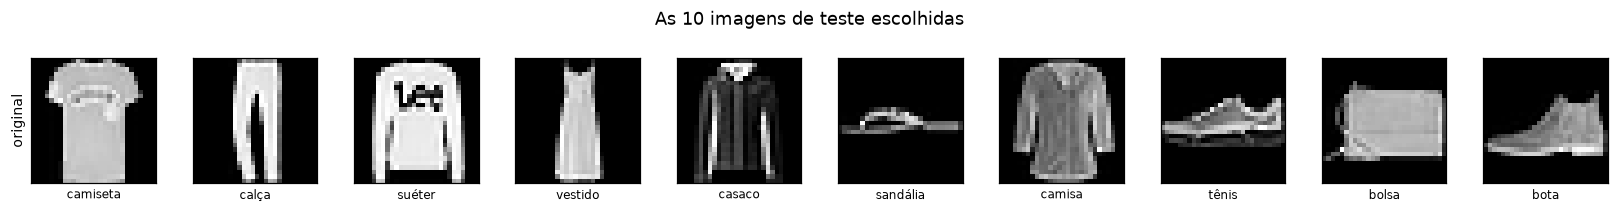

In [15]:
mostrar_linhas_de_imagens({"original": imagens_escolhidas}, "As 10 imagens de teste escolhidas",
                          textos={"original": CLASSES}, arquivo="5_escolhidas.png")

Escolhemos uma imagem de cada classe para ver como o autoencoder se sai em formas diferentes: peças simples e lisas (calça, vestido), peças com detalhes (estampa da camiseta, botões do casaco) e peças com formato mais complexo (sandália, tênis).

---
# Item a: autoencoders com tamanhos de espaço latente diferentes

## Arquitetura

In [16]:
for tamanho in TAMANHOS_LATENTE:
    modelo = Autoencoder(tamanho)
    print(f"Espaço latente com {tamanho} números: {sum(p.numel() for p in modelo.parameters()):,} pesos treináveis")
print()
print(Autoencoder(100))

Espaço latente com 100 números: 668,005 pesos treináveis
Espaço latente com 50 números: 354,355 pesos treináveis
Espaço latente com 30 números: 228,895 pesos treináveis

Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=100, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=100, out_features=3136, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (3): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (6): Sigmoid()
  )
)


Os três autoencoders são iguais, só muda o tamanho do espaço latente (a saída do encoder e a entrada do decoder). A imagem tem 784 pixels, então:
- com 100 números, a imagem é comprimida para cerca de 13% do tamanho original;
- com 50 números, para cerca de 6%;
- com 30 números, para cerca de 4%.

## Treinando os três modelos
Cada um treina por até 50 épocas, com lotes de 256 imagens e taxa de aprendizado 0,001. O treino para se a validação ficar 5 épocas sem melhorar.

In [17]:
modelos = {}
historicos = {}
for tamanho in TAMANHOS_LATENTE:
    fixar_semente()
    modelos[tamanho] = Autoencoder(tamanho).to(device)
    historicos[tamanho] = treinar(modelos[tamanho], imagens_treino, imagens_val, epocas=50, nome=f"Latente {tamanho}")

Latente 100:   0%|                                                                  | 0/50 [00:00<?, ?época/s]

Latente 100:   4%|▎        | 2/50 [00:02<00:49,  1.03s/época, erro_treino=0.01352, erro_val=0.01140, melhor=2]

Latente 100:  10%|▉        | 5/50 [00:04<00:38,  1.17época/s, erro_treino=0.00775, erro_val=0.00740, melhor=5]

Latente 100:  16%|█▍       | 8/50 [00:06<00:33,  1.24época/s, erro_treino=0.00617, erro_val=0.00603, melhor=8]

Latente 100:  22%|█▌     | 11/50 [00:08<00:30,  1.28época/s, erro_treino=0.00540, erro_val=0.00539, melhor=11]

Latente 100:  28%|█▉     | 14/50 [00:11<00:27,  1.29época/s, erro_treino=0.00494, erro_val=0.00501, melhor=14]

... (45 outputs left out)

Latente 30:  92%|███████▎| 46/50 [00:31<00:02,  1.49época/s, erro_treino=0.00722, erro_val=0.00743, melhor=46]

Latente 30:  98%|███████▊| 49/50 [00:33<00:00,  1.48época/s, erro_treino=0.00715, erro_val=0.00741, melhor=48]

Latente 30: 100%|████████| 50/50 [00:33<00:00,  1.48época/s, erro_treino=0.00714, erro_val=0.00744, melhor=48]

Melhor época: 48 (erro de validação = 0.00740)


## Curvas de erro de treino e de validação

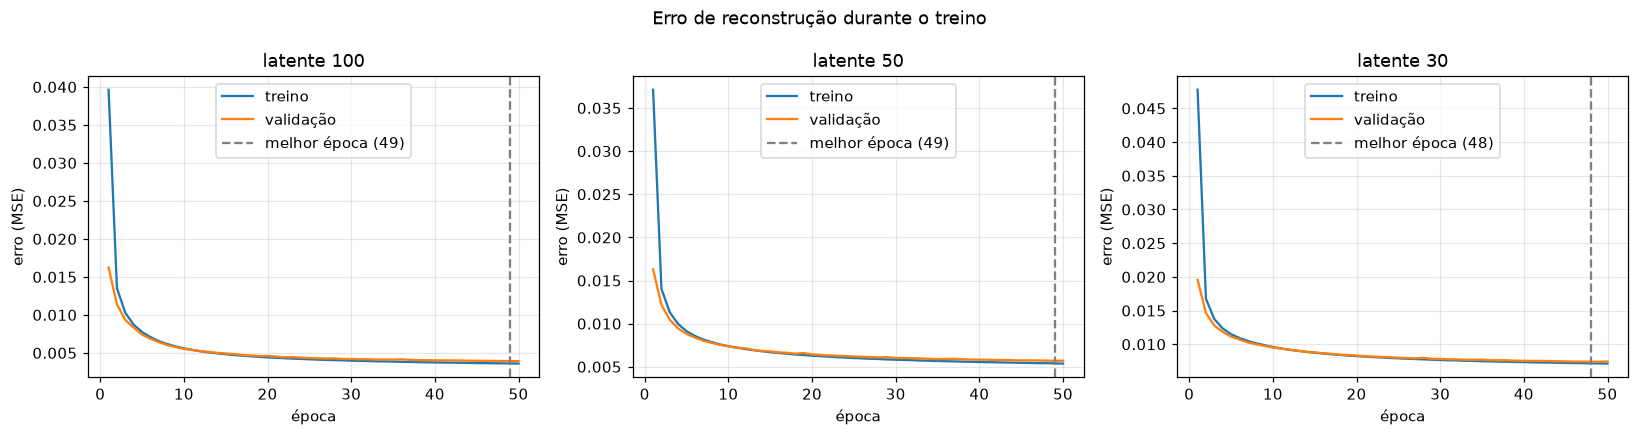

In [18]:
grafico_curvas({f"latente {t}": historicos[t] for t in TAMANHOS_LATENTE},
               "Erro de reconstrução durante o treino", arquivo="5a_curvas.png")

O que observar:
- Nos três modelos o erro cai muito nas primeiras 5 épocas e depois continua caindo devagar até o fim.
- As curvas de treino e de validação ficam praticamente uma em cima da outra. A rede não está decorando as imagens de treino.
- Quanto menor o espaço latente, maior o erro final: cerca de 0,004 com 100 números, 0,006 com 50 e 0,007 com 30. Com menos números a rede consegue guardar menos detalhes.
- A melhor época foi quase a última (48 ou 49 de 50), então os três modelos ainda não tinham parado de melhorar. A comparação entre eles vale para este limite de 50 épocas; treinando mais, os três erros cairiam um pouco, mas a melhora no final já é bem pequena.

## Erro de reconstrução no conjunto de teste inteiro

In [19]:
resumo = {}
for tamanho in TAMANHOS_LATENTE:
    reconstruidas = reconstruir(modelos[tamanho], imagens_teste)
    resumo[f"latente {tamanho}"] = {
        "MSE médio": erro_por_imagem(imagens_teste, reconstruidas).mean(),
        "PSNR médio (dB)": psnr(imagens_teste, reconstruidas).mean(),
    }
pd.DataFrame(resumo).T.round(5)

,MSE médio,PSNR médio (dB)
latente 100,0.00397,25.507099
latente 50,0.00575,23.820190
latente 30,0.00748,22.545481


## Erro de reconstrução nas 10 imagens escolhidas

In [20]:
reconstrucoes = {t: reconstruir(modelos[t], imagens_escolhidas) for t in TAMANHOS_LATENTE}

tabela_erros = pd.DataFrame(
    {f"latente {t}": erro_por_imagem(imagens_escolhidas, reconstrucoes[t]) for t in TAMANHOS_LATENTE},
    index=CLASSES,
)
tabela_erros.round(4)

,latente 100,latente 50,latente 30
camiseta,0.0015,0.0019,0.0024
calça,0.0007,0.0008,0.0011
suéter,0.0097,0.0166,0.0167
vestido,0.0009,0.0011,0.0017
casaco,0.0044,0.0079,0.0160
sandália,0.0013,0.0023,0.0042
camisa,0.0026,0.0039,0.0054
tênis,0.0029,0.0040,0.0060
bolsa,0.0028,0.0038,0.0046
bota,0.0009,0.0014,0.0023


## Gráfico do erro por imagem

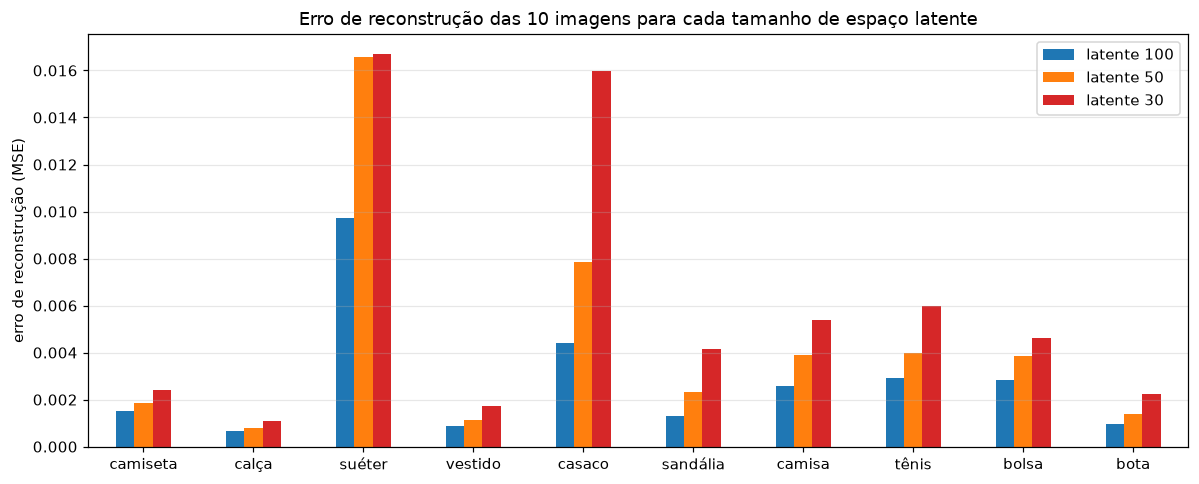

In [21]:
tabela_erros.plot.bar(figsize=(11, 4.5), rot=0, color=["tab:blue", "tab:orange", "tab:red"])
plt.ylabel("erro de reconstrução (MSE)")
plt.title("Erro de reconstrução das 10 imagens para cada tamanho de espaço latente")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "5a_erros_por_imagem.png", bbox_inches="tight")
plt.show()

O que observar:
- Em todas as 10 imagens o erro aumenta quando o espaço latente diminui (azul menor que laranja, que é menor que vermelho).
- As peças com formato simples e cor lisa (calça, vestido, bota) têm o menor erro: a rede só precisa guardar o contorno.
- O suéter tem de longe o maior erro (0,010 a 0,017), por causa do texto "Lee" escrito nele. O casaco também, por causa do zíper, dos bolsos e das linhas finas. São detalhes pequenos e únicos de cada peça, difíceis de guardar em poucos números.
- O casaco é a imagem que mais piora com o latente menor: o erro sobe de 0,0044 para 0,0160, cerca de 3,6 vezes.

## Imagens originais e reconstruídas

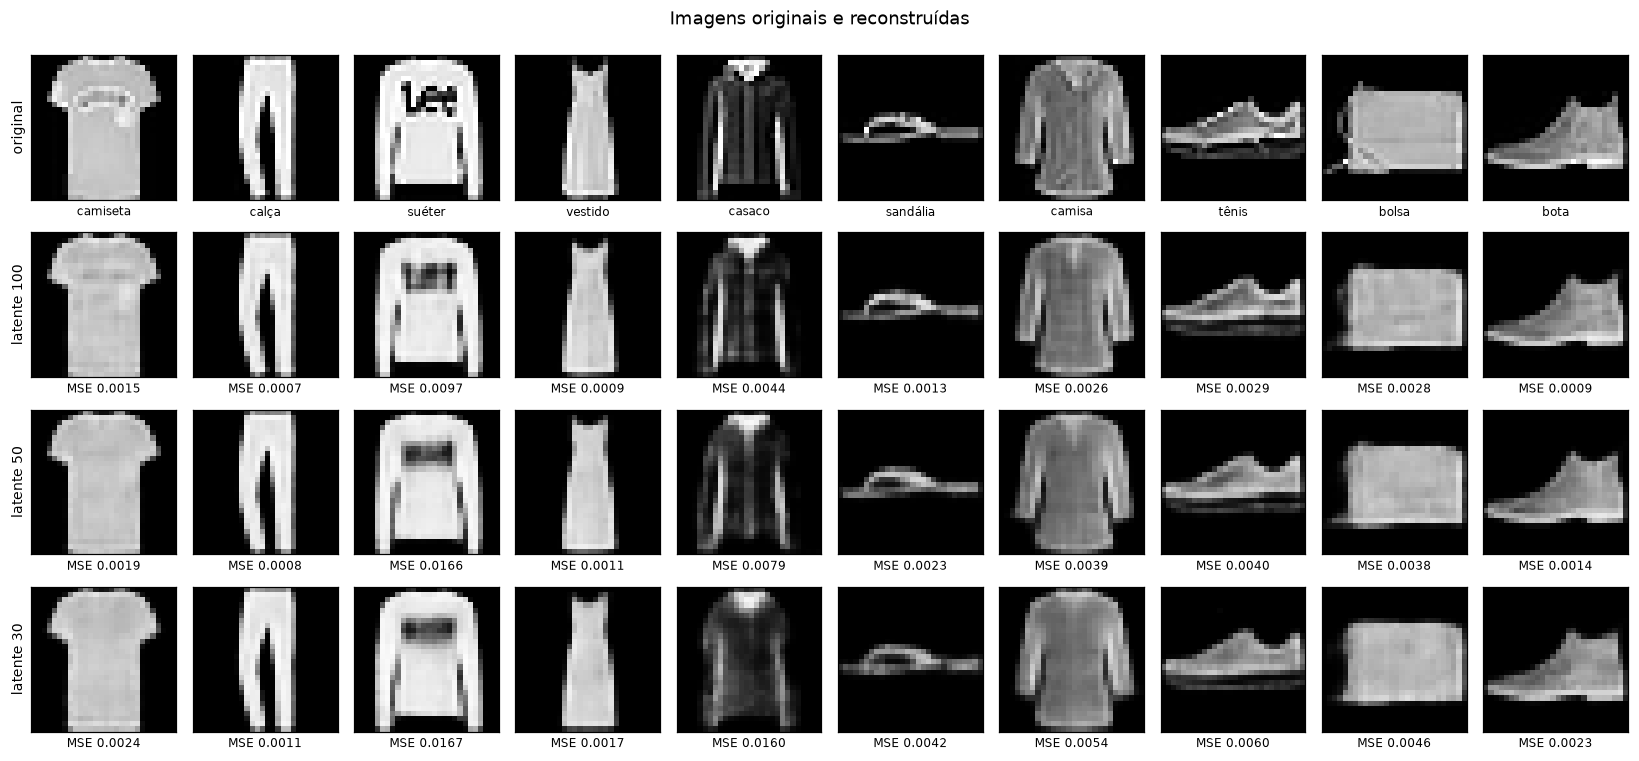

In [22]:
linhas = {"original": imagens_escolhidas}
textos = {"original": CLASSES}
for t in TAMANHOS_LATENTE:
    linhas[f"latente {t}"] = reconstrucoes[t]
    textos[f"latente {t}"] = [f"MSE {e:.4f}" for e in tabela_erros[f"latente {t}"]]

mostrar_linhas_de_imagens(linhas, "Imagens originais e reconstruídas", textos=textos, arquivo="5a_reconstrucoes.png")

O que observar:
- Os três modelos reconstroem bem o formato de todas as peças. Dá para reconhecer cada uma sem dificuldade.
- O que se perde são os detalhes finos. Com 100 números o texto "Lee" do suéter vira uma mancha em que ainda se percebem as letras, e as linhas do casaco continuam visíveis; a estampa da camiseta já vira um borrão. Com 50 e 30 números o texto vira uma faixa escura, a estampa some de vez e o casaco fica bem mais borrado.
- As reconstruções são sempre um pouco mais "lisas" e borradas que as originais. Isso é típico de autoencoders treinados com MSE: quando a rede não tem certeza de um detalhe, ela devolve uma média, que fica borrada.
- A bolsa perde a alça fina em todos os tamanhos de latente, e o tênis perde parte dos desenhos laterais.

## Verificando overfitting

In [23]:
tabela_overfitting = {}
for t in TAMANHOS_LATENTE:
    tabela_overfitting[f"latente {t}"] = {
        nome: erro_por_imagem(imagens, reconstruir(modelos[t], imagens)).mean()
        for nome, imagens in {"treino": imagens_treino, "validação": imagens_val, "teste": imagens_teste}.items()
    }
pd.DataFrame(tabela_overfitting).T.round(5)

,treino,validação,teste
latente 100,0.00355,0.00392,0.00397
latente 50,0.00533,0.00570,0.00575
latente 30,0.00710,0.00740,0.00748


O erro no treino é só um pouco menor que na validação e no teste (por exemplo, 0,0036 contra 0,0040 com latente 100). A validação e o teste têm praticamente o mesmo erro. Então não há overfitting relevante: os autoencoders reconstroem imagens novas quase tão bem quanto as de treino.

O gargalo do espaço latente ajuda nisso: como tudo tem que passar por poucos números, a rede é empurrada a guardar o que as peças têm em comum, e não os detalhes de cada imagem de treino.

---
# Item b: autoencoder para remover ruído

## Exemplo do ruído
Antes de treinar, vamos ver como fica uma imagem com o ruído que vamos usar (desvio de 0,3).

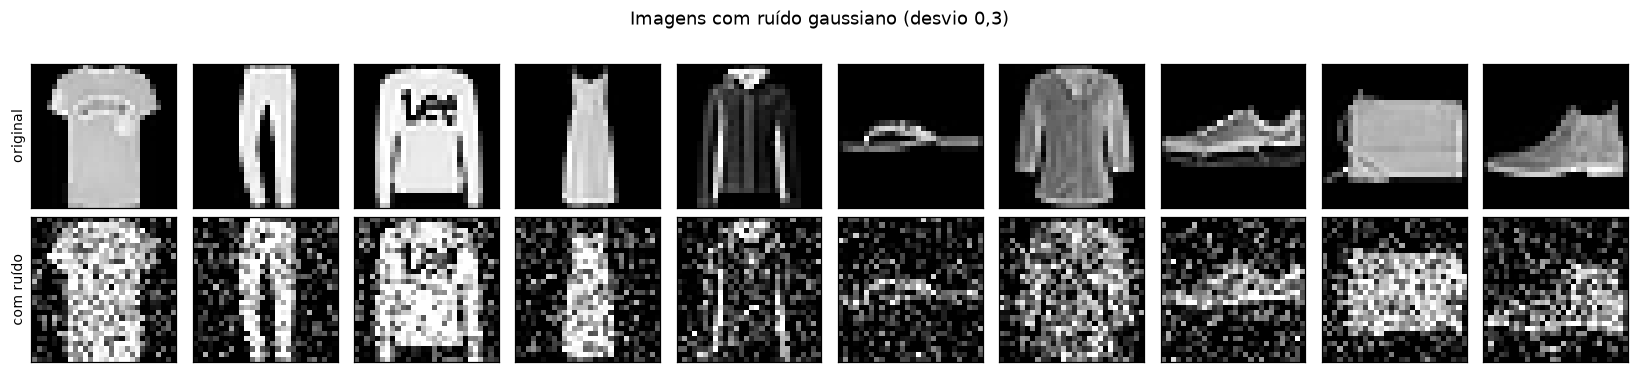

In [24]:
fixar_semente()
imagens_ruidosas = adicionar_ruido(imagens_escolhidas)
mostrar_linhas_de_imagens({"original": imagens_escolhidas, "com ruído": imagens_ruidosas},
                          "Imagens com ruído gaussiano (desvio 0,3)", arquivo="5b_ruido.png")

O ruído espalha "chuviscos" por toda a imagem, inclusive no fundo, que antes era preto. Os detalhes pequenos, como a estampa da camiseta e as tiras da sandália, ficam difíceis de ver.

Sobre o corte entre 0 e 1: um ruído gaussiano de desvio 0,3 teria MSE de 0,3² = 0,09 em relação à imagem limpa. Aqui o MSE medido fica perto de 0,05. A diferença vem do corte: no fundo preto (pixel 0) todo ruído negativo é cortado, e nas partes brancas (pixel 1) todo ruído positivo também. Então o ruído que a rede enfrenta é um pouco menor que 0,3 e não é mais simétrico: no fundo ele só clareia, nunca escurece.

## Arquitetura
Usamos a mesma arquitetura do item a, com espaço latente de 100 números. A diferença está só no treino: a entrada é a imagem com ruído e a saída esperada é a imagem limpa. Assim a rede aprende a "limpar" a imagem.

In [25]:
fixar_semente()
modelo_ruido = Autoencoder(100).to(device)
print(modelo_ruido)

Autoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=3136, out_features=100, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=100, out_features=3136, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(64, 7, 7))
    (3): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (6): Sigmoid()
  )
)


## Treinando

In [26]:
historico_ruido = treinar(modelo_ruido, imagens_treino, imagens_val, epocas=50, com_ruido=True, nome="Removendo ruído")

Removendo ruído:   0%|                                                              | 0/50 [00:00<?, ?época/s]

Removendo ruído:   6%|▎    | 3/50 [00:02<00:33,  1.40época/s, erro_treino=0.01401, erro_val=0.01315, melhor=3]

Removendo ruído:  12%|▌    | 6/50 [00:04<00:31,  1.39época/s, erro_treino=0.01101, erro_val=0.01074, melhor=6]

Removendo ruído:  18%|▉    | 9/50 [00:06<00:29,  1.38época/s, erro_treino=0.00989, erro_val=0.00979, melhor=9]

Removendo ruído:  24%|▋  | 12/50 [00:08<00:27,  1.38época/s, erro_treino=0.00931, erro_val=0.00930, melhor=12]

Removendo ruído:  30%|▉  | 15/50 [00:10<00:25,  1.38época/s, erro_treino=0.00894, erro_val=0.00894, melhor=15]

... (9 outputs left out)

Removendo ruído:  90%|██▋| 45/50 [00:32<00:03,  1.39época/s, erro_treino=0.00781, erro_val=0.00800, melhor=45]

Removendo ruído:  96%|██▉| 48/50 [00:34<00:01,  1.39época/s, erro_treino=0.00778, erro_val=0.00798, melhor=48]

Removendo ruído: 100%|███| 50/50 [00:36<00:00,  1.39época/s, erro_treino=0.00776, erro_val=0.00796, melhor=50]

Melhor época: 50 (erro de validação = 0.00796)


## Curvas de erro de treino e de validação

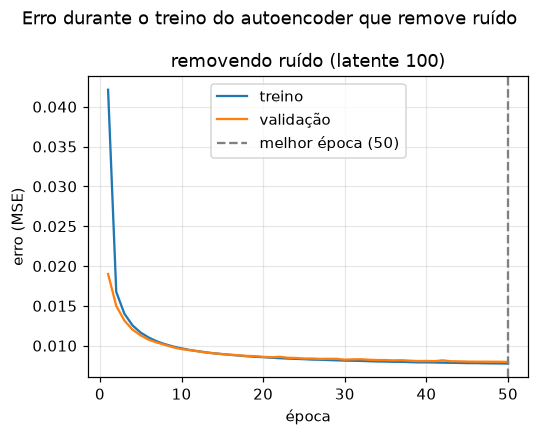

In [27]:
grafico_curvas({"removendo ruído (latente 100)": historico_ruido},
               "Erro durante o treino do autoencoder que remove ruído", arquivo="5b_curvas.png")

O que observar:
- O comportamento é parecido com o do item a: o erro cai rápido nas primeiras épocas e depois devagar, e treino e validação andam juntos.
- O erro final (cerca de 0,008) é maior que o do autoencoder normal com o mesmo tamanho de latente (0,004). Faz sentido, porque agora a tarefa é mais difícil: além de comprimir, a rede tem que adivinhar os pixels escondidos pelo ruído.
- Aqui também a melhor época foi a última (50), então o modelo ainda melhoraria um pouco com mais épocas.

## Imagens com ruído e reconstruídas
Usamos as mesmas 10 imagens do item a, com o mesmo ruído mostrado acima.

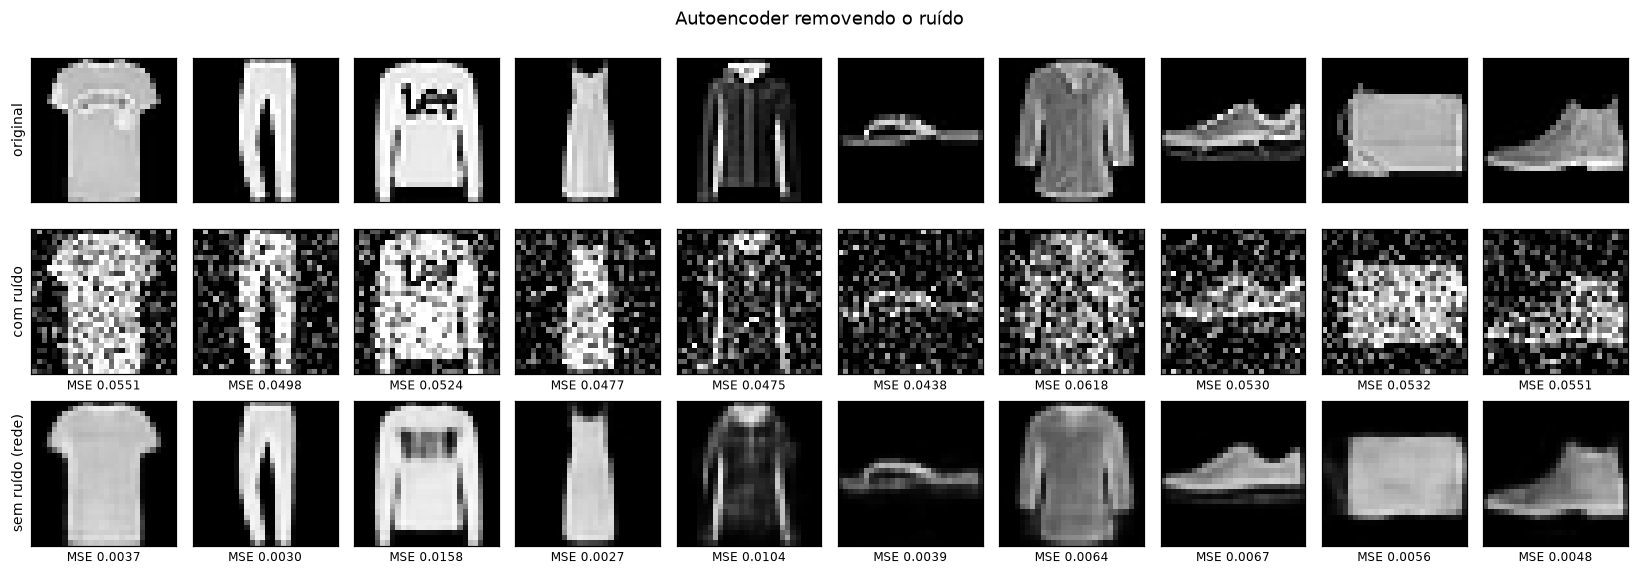

In [28]:
imagens_limpas = reconstruir(modelo_ruido, imagens_ruidosas)

mse_ruidosa = erro_por_imagem(imagens_escolhidas, imagens_ruidosas)
mse_limpa = erro_por_imagem(imagens_escolhidas, imagens_limpas)

mostrar_linhas_de_imagens(
    {"original": imagens_escolhidas, "com ruído": imagens_ruidosas, "sem ruído (rede)": imagens_limpas},
    "Autoencoder removendo o ruído",
    textos={"com ruído": [f"MSE {e:.4f}" for e in mse_ruidosa], "sem ruído (rede)": [f"MSE {e:.4f}" for e in mse_limpa]},
    arquivo="5b_reconstrucoes.png",
)

O que observar:
- As imagens com ruído (linha do meio) ficam bem difíceis de entender. Na sandália e na bota, quase não dá para ver a peça.
- A rede remove praticamente todo o ruído: o fundo volta a ficar preto e liso, e todas as peças voltam a ser reconhecíveis.
- O erro de cada imagem cai de cerca de 0,05 para algo entre 0,0027 e 0,016, ou seja, de 3 a 18 vezes menor.
- Como no item a, os detalhes finos se perdem: o texto do suéter vira uma faixa, a estampa da camiseta some e a alça da bolsa desaparece. O ruído escondeu esses detalhes e a rede preenche com o que é mais comum para aquele tipo de peça.

## Medindo a melhora
Comparamos cada imagem com a original: primeiro a versão com ruído e depois a versão limpa pela rede.

In [29]:
tabela_ruido = pd.DataFrame({
    "MSE com ruído": mse_ruidosa,
    "MSE depois da rede": mse_limpa,
    "PSNR com ruído (dB)": psnr(imagens_escolhidas, imagens_ruidosas),
    "PSNR depois da rede (dB)": psnr(imagens_escolhidas, imagens_limpas),
}, index=CLASSES)
tabela_ruido.loc["média"] = tabela_ruido.mean()
tabela_ruido.round(4)

,MSE com ruído,MSE depois da rede,PSNR com ruído (dB),PSNR depois da rede (dB)
camiseta,0.0551,0.0037,12.5869,24.364201
calça,0.0498,0.0030,13.0245,25.193501
suéter,0.0524,0.0158,12.8071,18.011400
vestido,0.0477,0.0027,13.2180,25.725500
casaco,0.0475,0.0104,13.2345,19.834900
sandália,0.0438,0.0039,13.5804,24.063101
camisa,0.0618,0.0064,12.0929,21.964100
tênis,0.0530,0.0067,12.7563,21.730400
bolsa,0.0532,0.0056,12.7448,22.496000
bota,0.0551,0.0048,12.5892,23.209600


Na média das 10 imagens, o MSE cai de 0,052 (com ruído) para 0,0063 (depois da rede), cerca de 8 vezes menor. O PSNR sobe de 12,9 dB para 22,7 dB, uma melhora de quase 10 dB.

A melhor reconstrução foi a do vestido (25,7 dB) e a pior foi a do suéter (18,0 dB), de novo por causa do texto escrito nele.

## Comparação com o autoencoder do item a
O gargalo do autoencoder já joga fora detalhes pequenos, e o ruído é um detalhe pequeno. Para ver se o autoencoder do item a (latente 100), que nunca viu ruído, também limparia as imagens, passamos as mesmas 10 imagens ruidosas pelos dois modelos.

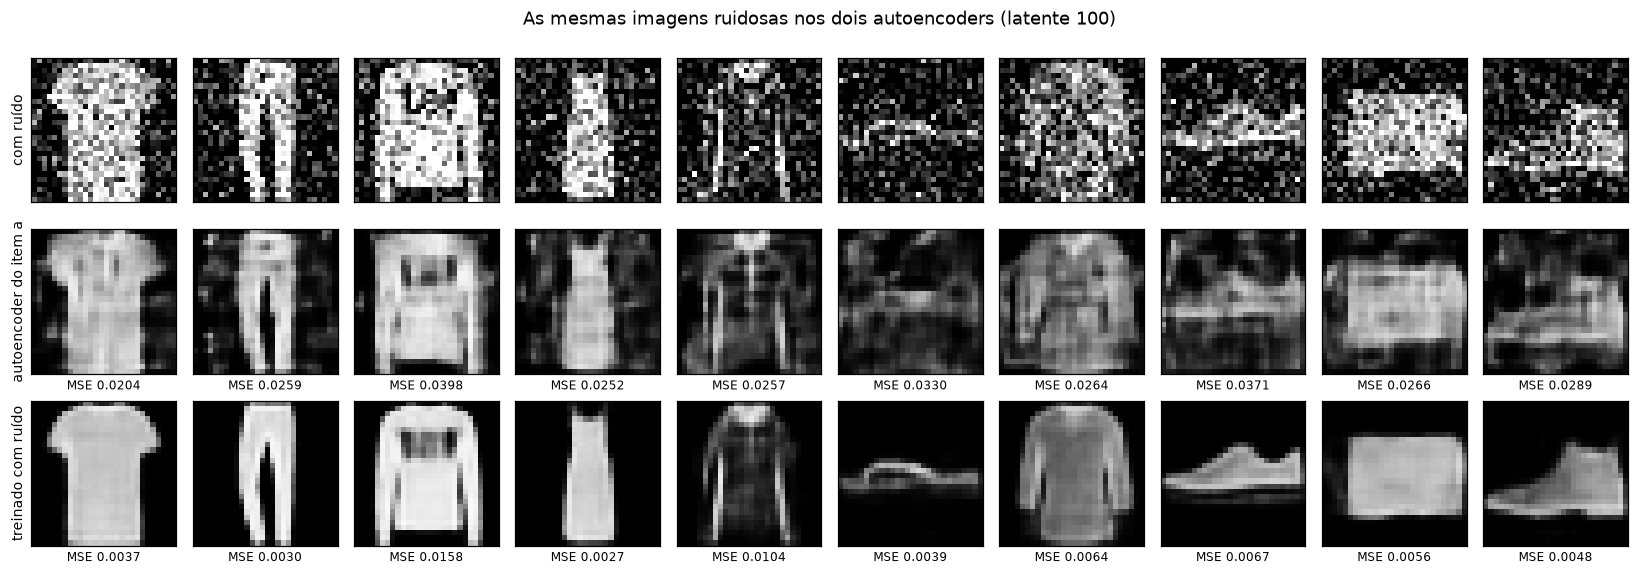

In [30]:
imagens_item_a = reconstruir(modelos[100], imagens_ruidosas)
mse_item_a = erro_por_imagem(imagens_escolhidas, imagens_item_a)

mostrar_linhas_de_imagens(
    {"com ruído": imagens_ruidosas, "autoencoder do item a": imagens_item_a, "treinado com ruído": imagens_limpas},
    "As mesmas imagens ruidosas nos dois autoencoders (latente 100)",
    textos={"autoencoder do item a": [f"MSE {e:.4f}" for e in mse_item_a], "treinado com ruído": [f"MSE {e:.4f}" for e in mse_limpa]},
    arquivo="5b_comparacao_item_a.png",
)

In [31]:
tabela_controle = pd.DataFrame({
    "MSE com ruído": mse_ruidosa,
    "MSE autoencoder do item a": mse_item_a,
    "MSE treinado com ruído": mse_limpa,
}, index=CLASSES)
tabela_controle.loc["média"] = tabela_controle.mean()
tabela_controle.round(4)

,MSE com ruído,MSE autoencoder do item a,MSE treinado com ruído
camiseta,0.0551,0.0204,0.0037
calça,0.0498,0.0259,0.0030
suéter,0.0524,0.0398,0.0158
vestido,0.0477,0.0252,0.0027
casaco,0.0475,0.0257,0.0104
sandália,0.0438,0.0330,0.0039
camisa,0.0618,0.0264,0.0064
tênis,0.0530,0.0371,0.0067
bolsa,0.0532,0.0266,0.0056
bota,0.0551,0.0289,0.0048


O que observar:
- O autoencoder do item a remove uma parte do ruído sozinho: na média das 10 imagens o MSE cai de 0,052 para 0,029, quase pela metade. As peças ficam reconhecíveis, porque o gargalo não tem espaço para guardar cada chuvisco.
- Mas o resultado é bem pior que o do autoencoder treinado com ruído (0,0063, mais de 4 vezes menor). Na figura, o fundo não volta a ficar preto: sobram manchas e "fantasmas" em volta das peças, principalmente na sandália, no tênis e na bota.
- O motivo é que o autoencoder do item a nunca viu ruído. Ele trata a imagem ruidosa como se fosse uma peça de verdade e tenta reconstruir o ruído também. O autoencoder do item b foi treinado para devolver a imagem limpa, então aprendeu que os chuviscos devem ser jogados fora.
- Então treinar com ruído faz diferença. O gargalo ajuda, mas responde por menos da metade da melhora.

## Verificando overfitting e o teste inteiro
Medimos o erro (comparando com a imagem limpa) em todas as imagens de treino, validação e teste, cada uma com um ruído novo.

In [32]:
fixar_semente()
linhas_ruido = {}
for nome, imagens in {"treino": imagens_treino, "validação": imagens_val, "teste": imagens_teste}.items():
    ruidosas = adicionar_ruido(imagens)
    linhas_ruido[nome] = {
        "MSE com ruído": erro_por_imagem(imagens, ruidosas).mean(),
        "MSE autoencoder do item a": erro_por_imagem(imagens, reconstruir(modelos[100], ruidosas)).mean(),
        "MSE depois da rede": erro_por_imagem(imagens, reconstruir(modelo_ruido, ruidosas)).mean(),
    }
pd.DataFrame(linhas_ruido).T.round(5)

,MSE com ruído,MSE autoencoder do item a,MSE depois da rede
treino,0.05255,0.02766,0.00770
validação,0.05256,0.02758,0.00795
teste,0.05266,0.02777,0.00801


O MSE depois da rede é 0,0077 no treino, 0,0080 na validação e 0,0080 no teste, quase iguais. A rede não decorou as imagens de treino e funciona do mesmo jeito em imagens novas.

Sorteamos um ruído novo a cada lote durante o treino. Por isso a rede nunca viu duas vezes a mesma imagem ruidosa, o que dificulta decorar.

A coluna do meio repete, no teste inteiro, a comparação com o autoencoder do item a: ele reduz o erro de 0,053 para 0,028, e o autoencoder treinado com ruído chega a 0,008.

---
# Conclusão

Item a
- Treinamos três autoencoders convolucionais, com espaços latentes de 100, 50 e 30 números.
- Quanto maior o espaço latente, melhor a reconstrução. No teste inteiro, o MSE foi de 0,0040, 0,0057 e 0,0075, e o PSNR de 25,5 dB, 23,8 dB e 22,5 dB.
- Os três modelos guardam bem o formato das peças, mesmo comprimindo 784 pixels em apenas 30 números (menos de 4% do tamanho). O que se perde primeiro são os detalhes finos e únicos: textos, estampas, zíperes e alças.
- Não houve overfitting relevante: treino, validação e teste têm praticamente o mesmo erro.

Item b
- O autoencoder treinado com imagens ruidosas aprendeu a remover o ruído. O MSE das 10 imagens caiu de 0,052 para 0,0063 e o PSNR subiu de 12,9 dB para 22,7 dB.
- As peças voltam a ficar reconhecíveis e o fundo fica limpo. Os detalhes finos escondidos pelo ruído não são recuperados: a rede os substitui pelo que é mais comum para aquele tipo de peça.
- Treinar com ruído é o que faz a diferença: o autoencoder do item a, que nunca viu ruído, só reduz o erro das mesmas imagens para 0,029.